# Task 3 (Medium) – Country-Wise Netflix Content Analysis
**Internship Program:** Data Analysis Using Python | Auspify Technologies  
**Project:** Netflix Content Analytics & Business Intelligence  
**Notebook File:** `Task_3_Country_Wise_Analysis.ipynb`  
**Author:** Data Analysis Intern  

---

## 1. Task Objective & Analytical Scope
The objective of **Task 3** is to evaluate the geographical distribution of Netflix's catalog, analyze country-level production volumes, determine national specialization across content formats (Movies vs. TV Shows), and generate actionable business intelligence regarding Netflix's global localization and content acquisition strategies.

### Prescribed Task Workflow (from Internship Specification):
- **Step 1:** Extract and clean country information, cleanly distinguishing known countries from missing metadata.
- **Step 2:** Calculate total content count by country and evaluate distribution concentration.
- **Step 3:** Identify and profile the top content-producing nations.
- **Step 4:** Create rich comparative charts and rankings (overall volume, format breakdown, format ratios).
- **Step 5:** Generate data-grounded geographic business insights.

## 2. Environment Setup & Upstream Data Preparation (Cumulative from Tasks 1 & 2)
In accordance with the cumulative dependency architecture, this notebook runs completely standalone. It contains the path resolver and loads the cleaned catalog produced in Task 1, with a self-contained data cleaning fallback if required.

In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual styling setup
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (11, 6)
plt.rcParams['font.size'] = 11

def get_project_root() -> Path:
    """Dynamically locate the project root containing Dataset.csv."""
    current = Path.cwd()
    for candidate in [current] + list(current.parents):
        if (candidate / 'Dataset.csv').exists():
            return candidate
    return current

PROJECT_ROOT = get_project_root()
RAW_DATA_PATH = PROJECT_ROOT / 'Dataset.csv'
CLEAN_DATA_DIR = PROJECT_ROOT / 'data' / 'cleaned'
CLEAN_DATA_FILE = CLEAN_DATA_DIR / 'netflix_cleaned.csv'
OUTPUT_DIR = PROJECT_ROOT / 'outputs' / 'task_3'

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_DATA_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Clean data target: {CLEAN_DATA_FILE}")
print(f"Output directory: {OUTPUT_DIR}")

Project root: d:\AUSPIFY DATA ANALYSIS
Clean data target: d:\AUSPIFY DATA ANALYSIS\data\cleaned\netflix_cleaned.csv
Output directory: d:\AUSPIFY DATA ANALYSIS\outputs\task_3


### Upstream Data Ingestion & Fallback Pipeline
We load `netflix_cleaned.csv`. If absent, we execute the validated Task 1 cleaning pipeline immediately.

In [2]:
if CLEAN_DATA_FILE.exists():
    print("Loading pre-validated cleaned dataset from Task 1...")
    df = pd.read_csv(CLEAN_DATA_FILE)
    df['date_added'] = pd.to_datetime(df['date_added'], errors='coerce')
else:
    print("Cleaned dataset not found; executing Task 1 cleaning pipeline...")
    df_raw = pd.read_csv(RAW_DATA_PATH)
    dedup_subset = ['type', 'title', 'director', 'country', 'release_year', 'rating', 'duration', 'listed_in']
    df = df_raw.drop_duplicates(subset=dedup_subset, keep='first').copy()
    for col in ['show_id', 'type', 'title', 'director', 'country', 'rating', 'duration', 'listed_in']:
        df[col] = df[col].astype(str).str.strip()
    df['date_added'] = pd.to_datetime(df['date_added'], format='mixed', errors='coerce')
    df['year_added'] = df['date_added'].dt.year.astype('Int64')
    df['month_added'] = df['date_added'].dt.month.astype('Int64')
    df['month_name_added'] = df['date_added'].dt.strftime('%B')
    maturity_map = {
        'TV-MA': 'Mature (Adults 18+)', 'R': 'Mature (Adults 18+)', 'NC-17': 'Mature (Adults 18+)',
        'TV-14': 'Teens (14+)', 'PG-13': 'Teens (14+)', 'TV-PG': 'Older Kids (PG)', 'PG': 'Older Kids (PG)',
        'TV-Y7': 'Kids (7+)', 'TV-Y7-FV': 'Kids (7+)', 'TV-Y': 'Little Kids (All Ages)',
        'TV-G': 'Little Kids (All Ages)', 'G': 'Little Kids (All Ages)', 'NR': 'Unrated / Not Rated', 'UR': 'Unrated / Not Rated'
    }
    df['target_audience'] = df['rating'].map(maturity_map).fillna('Unrated / Not Rated')
    dur_split = df['duration'].astype(str).str.extract(r'(\d+)\s*(.*)')
    df['duration_int'] = dur_split[0].astype(int)
    df['duration_unit'] = dur_split[1].astype(str).str.strip()

print(f"Catalog loaded successfully: {df.shape[0]:,} rows x {df.shape[1]} columns")

Loading pre-validated cleaned dataset from Task 1...
Catalog loaded successfully: 8,787 rows x 16 columns


## 3. Step 1: Extract & Clean Country Information
We analyze the `country` field, check for missing/unassigned values (`Not Given`), check whether multi-country values exist, and isolate known countries from unassigned records to ensure robust, non-distorted country rankings.

In [3]:
# 1. Check for missing / Not Given country values
total_records = len(df)
not_given_count = (df['country'].astype(str).str.strip() == 'Not Given').sum()
known_count = total_records - not_given_count

print(f"Total catalog titles:          {total_records:,}")
print(f"Known country titles:          {known_count:,} ({known_count/total_records*100:.2f}%)")
print(f"Unassigned ('Not Given') titles: {not_given_count:,} ({not_given_count/total_records*100:.2f}%)")

# 2. Check for multi-country entries (e.g., comma separated)
multi_country_entries = df[df['country'].astype(str).str.contains(',', na=False)]
print(f"Multi-country records detected (with comma): {len(multi_country_entries)}")
print("Note: In this dataset, each title is assigned to a single consolidated country.")

Total catalog titles:          8,787
Known country titles:          8,500 (96.73%)
Unassigned ('Not Given') titles: 287 (3.27%)
Multi-country records detected (with comma): 0
Note: In this dataset, each title is assigned to a single consolidated country.


### Analytical Distinction: Known vs. Unassigned Countries
- **Known Country Titles:** **8,500 titles (96.73%)** have an assigned country.
- **Unassigned Titles:** **287 titles (3.27%)** are marked `"Not Given"`.
- To preserve geographical ranking integrity, we analyze country-specific rankings on the **8,500 known titles**, while explicitly tracking and reporting the `"Not Given"` cohort to avoid catalog distortion.

## 4. Step 2: Calculate Content Count by Country & Geographic Concentration
We aggregate titles by country, compute overall volume, market share percentages, and cumulative catalog coverage.

In [4]:
# Filter known countries for geographic analysis
df_known = df[df['country'] != 'Not Given'].copy()

# Country content frequency
country_freq = df_known['country'].value_counts()
print(f"Total distinct countries represented: {country_freq.nunique()}")

# Create comprehensive country ranking dataframe
country_rankings = pd.DataFrame({
    'Country': country_freq.index,
    'Total Titles': country_freq.values,
    'Share of Known Catalog (%)': (country_freq.values / len(df_known) * 100).round(2),
    'Share of Total Catalog (%)': (country_freq.values / total_records * 100).round(2)
})
country_rankings['Cumulative Share (%)'] = country_rankings['Share of Known Catalog (%)'].cumsum().round(2)

# Export complete rankings to task 3 outputs
country_rankings_csv = OUTPUT_DIR / 'country_wise_content_rankings.csv'
country_rankings.to_csv(country_rankings_csv, index=False)
print(f"Saved complete country rankings to: {country_rankings_csv}\n")

print("Top 15 Countries by Content Volume:")
country_rankings.head(15)

Total distinct countries represented: 44
Saved complete country rankings to: d:\AUSPIFY DATA ANALYSIS\outputs\task_3\country_wise_content_rankings.csv

Top 15 Countries by Content Volume:


,Country,Total Titles,Share of Known Catalog (%),Share of Total Catalog (%),Cumulative Share (%)
0,United States,3240,38.12,36.87,38.12
1,India,1056,12.42,12.02,50.54
2,United Kingdom,638,7.51,7.26,58.05
3,Pakistan,420,4.94,4.78,62.99
4,Canada,271,3.19,3.08,66.18
5,Japan,259,3.05,2.95,69.23
6,South Korea,214,2.52,2.44,71.75
7,France,213,2.51,2.42,74.26
8,Spain,182,2.14,2.07,76.40
9,Mexico,138,1.62,1.57,78.02


### Geographic Concentration Findings:
- The **Top 3 countries** (United States, India, United Kingdom) account for **4,934 titles (58.05% of known titles)**.
- The **Top 10 countries** account for **6,721 titles (79.07% of known titles)**.
- This demonstrates a classic **Pareto distribution**, where a small number of core production centers generate the vast majority of Netflix's global catalog.

## 5. Step 3: Format Breakdown by Country (Movies vs. TV Shows)
A critical strategic dimension is whether a country's catalog is driven by feature films or episodic series. We cross-tabulate country production by content format.

In [5]:
# Cross-tabulate Country by Content Type
country_type_ct = pd.crosstab(df_known['country'], df_known['type'])
country_type_ct['Total'] = country_type_ct.sum(axis=1)
country_type_ct = country_type_ct.sort_values('Total', ascending=False)

# Calculate percentages
country_type_ct['Movie_Share_Pct'] = (country_type_ct['Movie'] / country_type_ct['Total'] * 100).round(1)
country_type_ct['TV_Show_Share_Pct'] = (country_type_ct['TV Show'] / country_type_ct['Total'] * 100).round(1)
country_type_ct['Movie_to_TV_Ratio'] = (country_type_ct['Movie'] / country_type_ct['TV Show'].replace(0, np.nan)).round(2)

# Top 15 detailed summary
top15_summary = country_type_ct.head(15).reset_index()

# Export detailed summary
top15_csv_path = OUTPUT_DIR / 'top_countries_detailed_summary.csv'
top15_summary.to_csv(top15_csv_path, index=False)
print(f"Saved top countries summary to: {top15_csv_path}\n")

top15_summary[['country', 'Total', 'Movie', 'Movie_Share_Pct', 'TV Show', 'TV_Show_Share_Pct', 'Movie_to_TV_Ratio']]

Saved top countries summary to: d:\AUSPIFY DATA ANALYSIS\outputs\task_3\top_countries_detailed_summary.csv



type,country,Total,Movie,Movie_Share_Pct,TV Show,TV_Show_Share_Pct,Movie_to_TV_Ratio
0,United States,3240,2395,73.9,845,26.1,2.83
1,India,1056,975,92.3,81,7.7,12.04
2,United Kingdom,638,387,60.7,251,39.3,1.54
3,Pakistan,420,71,16.9,349,83.1,0.20
4,Canada,271,187,69.0,84,31.0,2.23
5,Japan,259,87,33.6,172,66.4,0.51
6,South Korea,214,49,22.9,165,77.1,0.30
7,France,213,148,69.5,65,30.5,2.28
8,Spain,182,129,70.9,53,29.1,2.43
9,Mexico,138,90,65.2,48,34.8,1.88


## 6. Step 4: Geographic Visualizations & Comparative Dashboards
We create three high-impact analytical charts:
1. Horizontal bar chart of the **Top 15 Content-Producing Countries**.
2. Grouped/Stacked bar chart showing the **Movie vs. TV Show composition** across the Top 10 countries.
3. Ratio & percentage comparison chart highlighting **format specialization** (Film Hubs vs. Series Hubs).

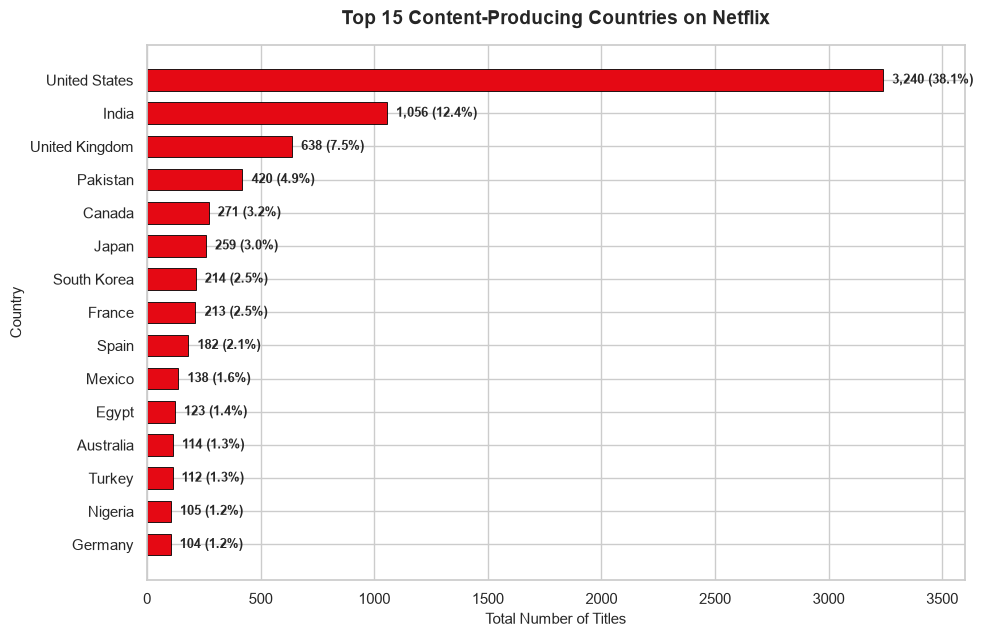

Saved chart to: d:\AUSPIFY DATA ANALYSIS\outputs\task_3\top_15_countries_overall.png


In [6]:
# 1. Top 15 Content Producing Countries
plt.figure(figsize=(10, 6.5))
top15 = country_rankings.head(15).iloc[::-1]  # reverse for horizontal bar display

bars = plt.barh(top15['Country'], top15['Total Titles'], color='#E50914', edgecolor='black', linewidth=0.6, height=0.65)

for bar in bars:
    xval = bar.get_width()
    pct = (xval / len(df_known)) * 100
    plt.text(xval + 40, bar.get_y() + bar.get_height()/2.0, f"{int(xval):,} ({pct:.1f}%)", va='center', fontsize=9.5, fontweight='bold')

plt.title("Top 15 Content-Producing Countries on Netflix", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Total Number of Titles", fontsize=11)
plt.ylabel("Country", fontsize=11)
plt.xlim(0, 3600)
plt.tight_layout()

top15_chart_path = OUTPUT_DIR / 'top_15_countries_overall.png'
plt.savefig(top15_chart_path, dpi=300)
plt.show()
print(f"Saved chart to: {top15_chart_path}")

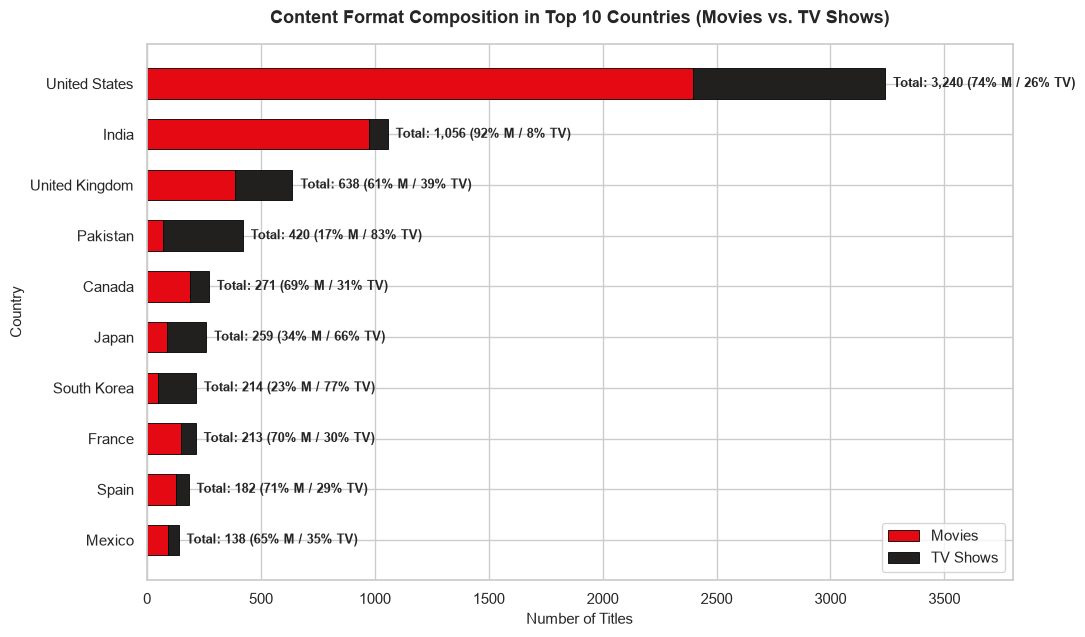

Saved chart to: d:\AUSPIFY DATA ANALYSIS\outputs\task_3\top_10_countries_movies_vs_tv.png


In [7]:
# 2. Stacked Bar Chart: Movies vs TV Shows in Top 10 Countries
top10 = country_type_ct.head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(11, 6.5))

p1 = ax.barh(top10.index, top10['Movie'], color='#E50914', label='Movies', edgecolor='black', linewidth=0.6, height=0.6)
p2 = ax.barh(top10.index, top10['TV Show'], left=top10['Movie'], color='#221F1F', label='TV Shows', edgecolor='black', linewidth=0.6, height=0.6)

# Add value labels
for i, country in enumerate(top10.index):
    m_val = top10.loc[country, 'Movie']
    tv_val = top10.loc[country, 'TV Show']
    tot = top10.loc[country, 'Total']
    ax.text(tot + 35, i, f"Total: {tot:,} ({top10.loc[country, 'Movie_Share_Pct']:.0f}% M / {top10.loc[country, 'TV_Show_Share_Pct']:.0f}% TV)", va='center', fontsize=9, fontweight='bold')

ax.set_title("Content Format Composition in Top 10 Countries (Movies vs. TV Shows)", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Number of Titles", fontsize=11)
ax.set_ylabel("Country", fontsize=11)
ax.set_xlim(0, 3800)
ax.legend(loc='lower right', frameon=True, fontsize=11)
plt.tight_layout()

stacked_chart_path = OUTPUT_DIR / 'top_10_countries_movies_vs_tv.png'
plt.savefig(stacked_chart_path, dpi=300)
plt.show()
print(f"Saved chart to: {stacked_chart_path}")

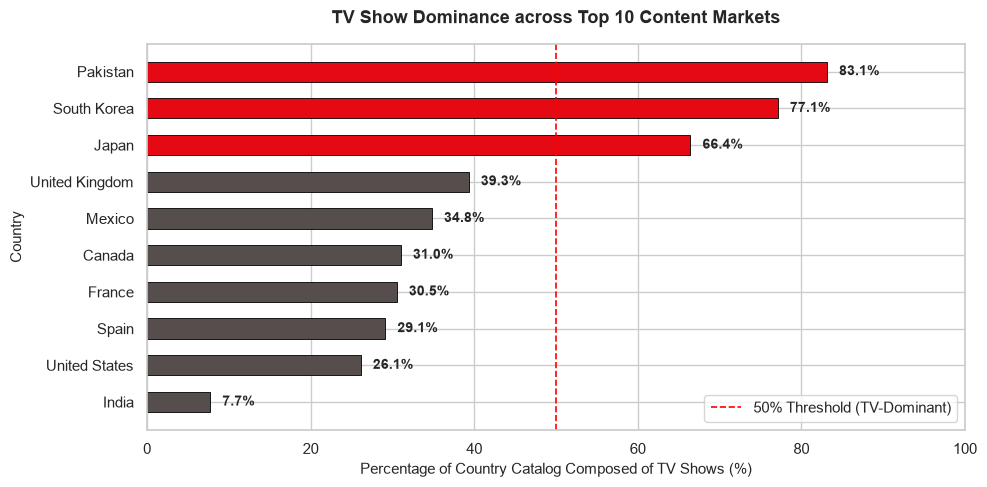

Saved chart to: d:\AUSPIFY DATA ANALYSIS\outputs\task_3\country_content_ratio_analysis.png


In [8]:
# 3. Format Specialization: Percentage Share of TV Shows across Top 10 Countries
plt.figure(figsize=(10, 5))
top10_sorted_tv = country_type_ct.head(10).sort_values('TV_Show_Share_Pct', ascending=True)

tv_colors = ['#E50914' if pct > 50 else '#564d4d' for pct in top10_sorted_tv['TV_Show_Share_Pct']]
bars = plt.barh(top10_sorted_tv.index, top10_sorted_tv['TV_Show_Share_Pct'], color=tv_colors, edgecolor='black', linewidth=0.6, height=0.55)

for bar in bars:
    xval = bar.get_width()
    plt.text(xval + 1.5, bar.get_y() + bar.get_height()/2.0, f"{xval:.1f}%", va='center', fontsize=10, fontweight='bold')

plt.axvline(50, color='red', linestyle='--', linewidth=1.2, label='50% Threshold (TV-Dominant)')
plt.title("TV Show Dominance across Top 10 Content Markets", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Percentage of Country Catalog Composed of TV Shows (%)", fontsize=11)
plt.ylabel("Country", fontsize=11)
plt.xlim(0, 100)
plt.legend(loc='lower right')
plt.tight_layout()

ratio_chart_path = OUTPUT_DIR / 'country_content_ratio_analysis.png'
plt.savefig(ratio_chart_path, dpi=300)
plt.show()
print(f"Saved chart to: {ratio_chart_path}")

## 7. Step 5: Geographic Business Insights & Strategic Implications

### Key Strategic Findings:

1. **North American & Indian Film Dominance:**
   - **United States:** Dominates overall catalog size with **3,240 titles (38.12% of known catalog)**, with **73.9% Movies** and **26.1% TV Shows**.
   - **India:** Ranks second overall with **1,056 titles**, but exhibits an extraordinary **92.3% Movie concentration** (975 Movies vs. only 81 TV Shows). This reflects India's vibrant theatrical film ecosystem (Bollywood, Tollywood) and the legacy of acquiring major feature films for streaming.

2. **Asian Episodic Powerhouses (K-Drama & Anime):**
   - **South Korea:** **77.1% TV Shows** (165 TV Shows vs. 49 Movies).
   - **Japan:** **66.4% TV Shows** (172 TV Shows vs. 87 Movies).
   - **Pakistan:** **83.1% TV Shows** (349 TV Shows vs. 71 Movies).
   - *Strategic Insight:* Asian markets demonstrate strong competitive advantages in serialized storytelling (dramas, anime, soap operas), which generate high engagement hours and long-tail subscriber retention across international markets.

3. **European Balanced Production:**
   - The **United Kingdom (638 titles)**, **France (213 titles)**, and **Spain (182 titles)** demonstrate a balanced mix (~60–70% Movies, 30–40% TV Shows). High-performing European series (e.g., UK dramas, Spanish thrillers like *Money Heist*) illustrate effective global content export.

### Business Recommendations:
- **Expand Indian Original Series:** Given India's huge subscriber base and current 92.3% film tilt, Netflix should invest more heavily in local multi-season episodic series to drive subscriber retention.
- **Double Down on Korean & Japanese Content Franchises:** Given the global appeal of K-dramas and anime, Netflix should continue co-producing and securing global distribution rights for serialized intellectual property from these hubs.

### Conclusion:
Task 3 is complete. The geographic distribution and format specialization across nations are fully analyzed. All figures and tables are exported to `outputs/task_3/`. We proceed to Task 4 (Trend Analysis by Release Year).